# Analysis Charts

Charts for each finding in [docs/findings.md](../docs/findings.md). Queries run from `sql/analysis/`.

In [1]:
import sqlite3
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter as pct
import pandas as pd

ROOT = Path("..").resolve()
conn = sqlite3.connect(ROOT / "olist_clean.db")

def run_query(name):
    sql = (ROOT / "sql" / "analysis" / name).read_text()
    return pd.read_sql_query(sql, conn)

## Monthly Orders

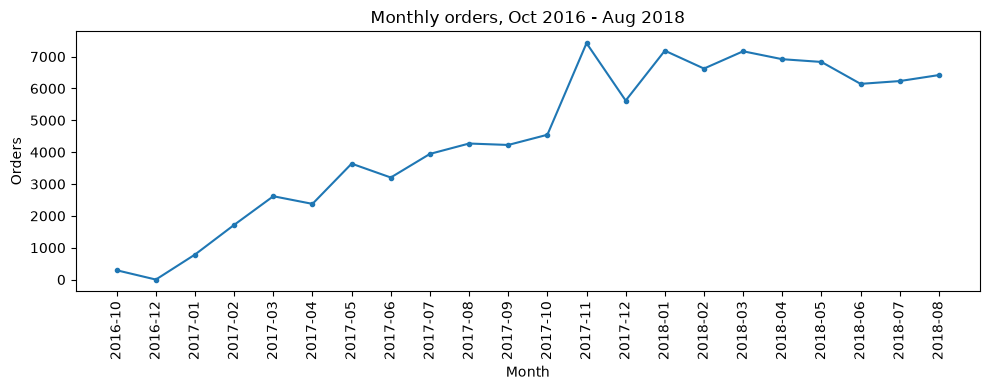

In [2]:
monthly = run_query("01_monthly_orders.sql")
monthly = monthly[monthly["month"].between("2016-10", "2018-08")]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly["month"], monthly["order_count"], marker="o", markersize=3)
ax.set_title("Monthly orders, Oct 2016 - Aug 2018")
ax.set_xlabel("Month")
ax.set_ylabel("Orders")
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

## Delivery SLA

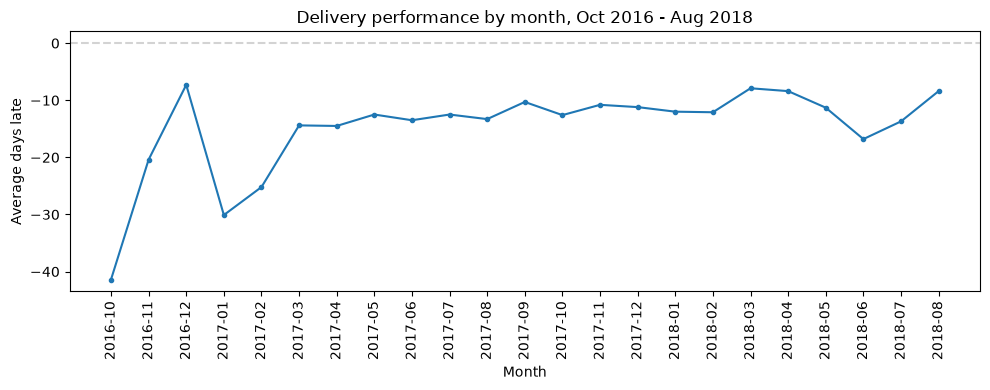

In [3]:
monthly = run_query("02_delivery_sla.sql")
monthly = monthly[monthly["delivered_month"].between("2016-10", "2018-08")]

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(monthly["delivered_month"], monthly["avg_days_late"], marker="o", markersize=3)
ax1.axhline(0, linestyle="--", color="lightgrey")
ax1.set_title("Delivery performance by month, Oct 2016 - Aug 2018")
ax1.set_xlabel("Month")
ax1.set_ylabel("Average days late")
ax1.tick_params(axis="x", rotation=90)

plt.tight_layout()
plt.show()

## Review Drivers

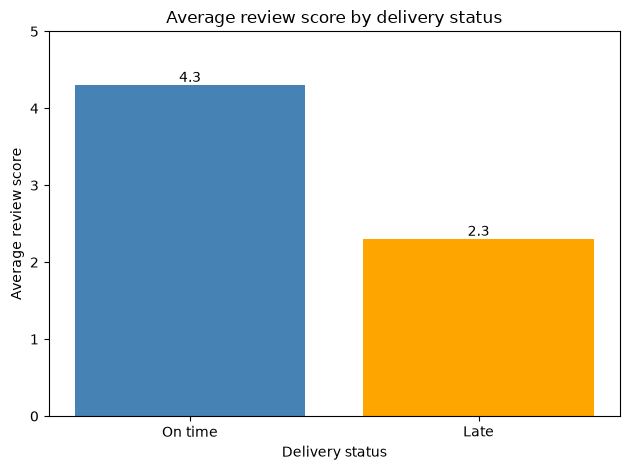

In [4]:
status = run_query("03_review_drivers.sql")

colors = {
    "On time": "steelblue",
    "Late": "orange",
}
bar_colors = [
    colors.get(delivery_status, "gray")
    for delivery_status in status["delivery_status"]
]

fig, ax = plt.subplots()
ax.bar(status["delivery_status"], status["avg_review_score"], color=bar_colors)

ax.set_title("Average review score by delivery status")
ax.bar_label(ax.containers[0])
ax.set_xlabel("Delivery status")
ax.set_ylabel("Average review score")
ax.set_ylim(0, 5)

plt.tight_layout()
plt.show()

## Repeat Buyers

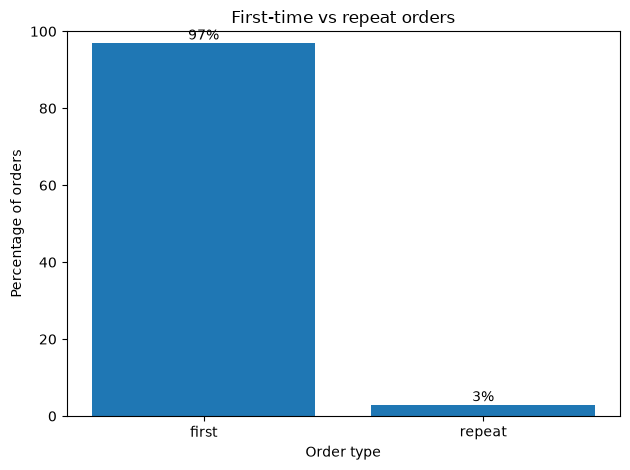

In [5]:
status = run_query("04_repeat_buyers.sql")

fig, ax = plt.subplots()
ax.bar(status["customer_type"], status["share_pct"])

ax.set_title("First-time vs repeat orders")
ax.bar_label(ax.containers[0], labels=[f"{value:.0f}%" for value in status["share_pct"]],)
ax.set_xlabel("Order type")
ax.set_ylabel("Percentage of orders")
ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()

## Payment Mix

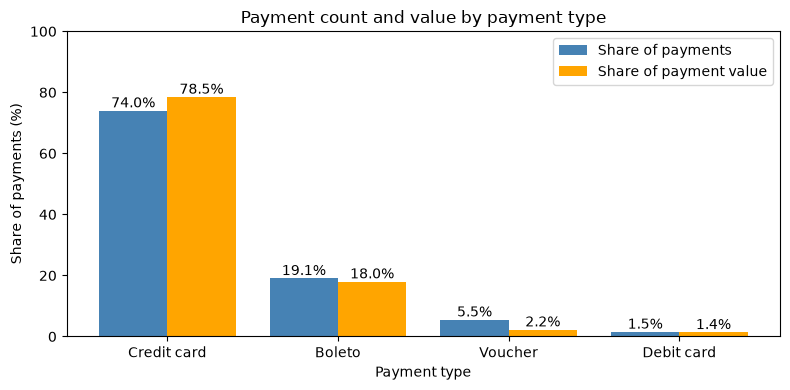

In [6]:
payments = run_query("05_payment_mix.sql")

x = np.arange(len(payments["payment_type"]))
width = 0.4

fig, ax = plt.subplots(figsize=(8, 4))

bars1 = ax.bar(
    x - width / 2,
    payments["share_pct"],
    width,
    label="Share of payments",
    color="steelblue"
)

bars2 = ax.bar(
    x + width / 2,
    payments["value_pct"],
    width,
    label="Share of payment value",
    color="orange"
)

ax.set_title("Payment count and value by payment type")
ax.set_xlabel("Payment type")
ax.set_ylabel("Share of payments (%)")
ax.set_xticks(x)
ax.set_xticklabels(payments["payment_type"])
ax.set_ylim(0, 100)
ax.legend()

ax.bar_label(bars1, fmt="%.1f%%")
ax.bar_label(bars2, fmt="%.1f%%")

plt.tight_layout()
plt.show()